In [1]:
import wandb
import numpy as np
import pandas as pd

from matplotlib import pyplot as plt

In [2]:
api = wandb.Api(api_key='4a3e44e53460799e4aae1531c4bdfbd4e22f82ce')
path = 'kprotopapas/rl_experiments'
alg = 'deqa'

In [3]:
def get_runs(group, n, metric='suboptimality'):
    runs = api.runs(path=path, filters={'group': group, 'tags': {'$ne': 'outlier'}})
    dfs = {d: [] for d in [1, 5, 10, 15, 20]}
    for run in runs:
        cutoff = 5 if 'J' in run.config['algorithm'] else 4
        depth = int(run.config['algorithm'][:-cutoff])
        if len(dfs[depth]) >= n:
            continue
        temp = run.history(keys=[metric, 'runtime', 'learning_rate'], x_axis='_step')\
            .rename(columns={'_step': 'k', metric: f'{metric}'})
        
        if len(temp) > 80:    
            temp = temp.set_index('k')
            dfs[depth].append(temp)

    return dfs

In [4]:
dfs_inexact = get_runs(f'{alg}_time', 32)

In [5]:
subopts = {k: [df['suboptimality'] for df in dfs] for k, dfs in dfs_inexact.items()}
times = {k: [df['runtime'] for df in dfs] for k, dfs in dfs_inexact.items()}
lrs = {k: [df['learning_rate'] for df in dfs] for k, dfs in dfs_inexact.items()}

In [6]:
def process(df):
    joined = {k: pd.concat(v, axis=1) for k, v in df.items()}
    stds = {k: v.std(axis=1).rename(f'{k}-std') for k, v in joined.items()}
    means = {k: v.mean(axis=1).rename(f'{k}-mean') for k, v in joined.items()}
    means_df = pd.concat(means.values(), axis=1)
    stds_df = pd.concat(stds.values(), axis=1)
    means_df = means_df - means_df.min()
    
    return means_df, stds_df

In [7]:
#means_exact, stds_exact = process(dfs_exact)
sub_means, sub_stds = process(subopts)
time_means, time_stds = process(times)
lrs_means, lrs_stds = process(lrs)

#means_fixed, stds_fixed = process(dfs_fixed)

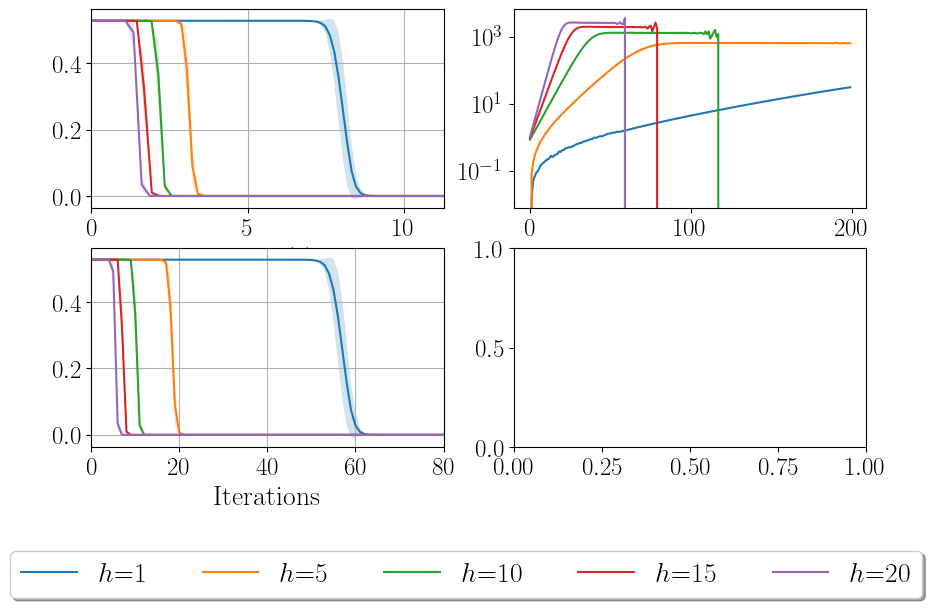

In [11]:
import matplotlib.pyplot as plt
# choose a large font size by default and use tex for math
fontsize = 18
params = {'axes.labelsize': fontsize + 2,
      'font.size': fontsize + 2,
      'legend.fontsize': fontsize + 2,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'text.usetex': True,
      'figure.figsize': (10, 6)}
plt.rcParams.update(params)
plt.rc('font', family='Times New Roman')
fig, axes = plt.subplots(2, 2)

plt.gca().set_prop_cycle(None)
axes[0, 0].plot(time_means, sub_means)
for name, std in sub_stds.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = sub_means[mean_name]
    axes[0, 0].fill_between(time_means[mean_name],
                        mean - std, mean + std, alpha=0.2)
    
axes[0, 0].grid(visible=True)
axes[0, 0].set_xlabel('Time (s)')
axes[0, 0].set_xlim(0, time_means['1-mean'].iloc[80])

plt.gca().set_prop_cycle(None)
axes[1, 0].plot(sub_means)
for name, std in sub_stds.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = sub_means[mean_name]
    axes[1, 0].fill_between(mean.index,
                        mean - std, mean + std, alpha=0.2)

axes[1, 0].grid(visible=True)
axes[1, 0].set_xlabel('Iterations')
axes[1, 0].set_xlim(0, 80)

axes[0, 1].plot(lrs_means)
axes[0, 1].set_yscale('log')

legends = [f'$h$={depth}' for depth in [1, 5, 10, 15, 20]]

plt.subplots_adjust(bottom=0.15)

lgd = fig.legend(legends, loc='upper center', bbox_to_anchor=(0.5, 0),
          fancybox=True, shadow=True, ncol=5)

fig.savefig(f'{alg}_time.pdf', bbox_extra_artists=(lgd,), bbox_inches='tight')


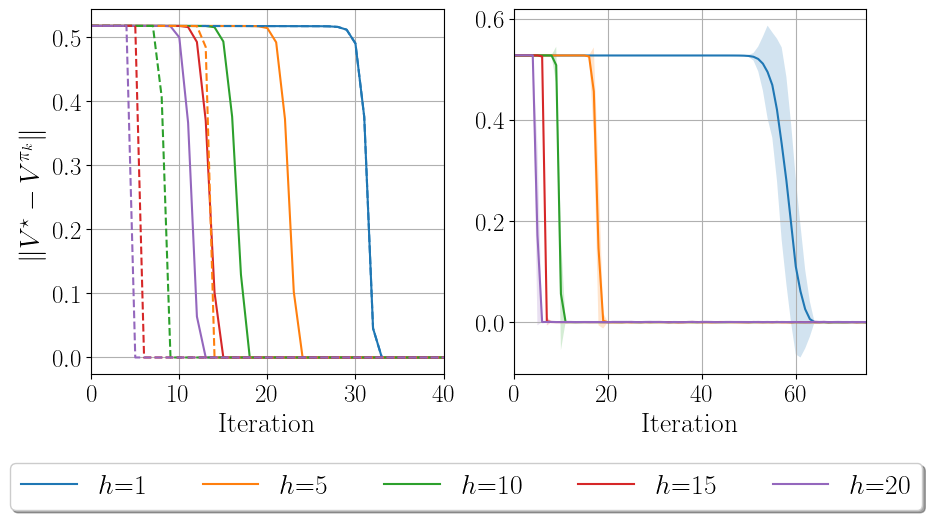

In [ ]:
import matplotlib.pyplot as plt
# choose a large font size by default and use tex for math
fontsize = 18
params = {'axes.labelsize': fontsize + 2,
      'font.size': fontsize + 2,
      'legend.fontsize': fontsize + 2,
      'xtick.labelsize': fontsize,
      'ytick.labelsize': fontsize,
      'text.usetex': True}
plt.rcParams.update(params)
plt.rc('font', family='Times New Roman')
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].set_prop_cycle(None)
axes[0].plot(means_fixed)
axes[0].set_prop_cycle(None)
axes[0].plot(means_exact, linestyle='dashed')
for name, std in stds_exact.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = means_exact[mean_name]
    mean_fixed = means_fixed[mean_name]
    std_fixed = stds_fixed[name]
    axes[0].fill_between(std.index, mean - std, mean + std, alpha=0.2)
    axes[0].fill_between(std_fixed.index, mean_fixed - std_fixed, mean_fixed + std_fixed, alpha=0.2)

plt.gca().set_prop_cycle(None)
axes[1].plot(means_inexact)
for name, std in stds_inexact.items():
    depth = int(name[:-4])
    mean_name = f'{depth}-mean'
    mean = means_inexact[mean_name]
    axes[1].fill_between(std.index, mean - std, mean + std, alpha=0.2)


axes[0].grid(visible=True)
axes[0].set_xlabel('Iteration')
axes[0].set_ylabel('Samples')
axes[0].set_xlim(0, 40)

axes[1].grid(visible=True)
axes[1].set_xlabel('Iteration')
axes[1].set_xlim(0, 75)

legends = [f'$h$={depth}' for depth in [1, 5, 10, 15, 20]]

plt.subplots_adjust(bottom=0.15)

lgd = fig.legend(legends, loc='upper center', bbox_to_anchor=(0.5, 0),
          fancybox=True, shadow=True, ncol=5)

fig.savefig(f'{alg}_triple.pdf', bbox_extra_artists=(lgd,), bbox_inches='tight')
